# MADA - Resultados Unificados: Análise Comparativa

**Metodologia de Amplificação de Divergências Anotativas**

Este notebook apresenta a análise unificada e comparativa dos resultados obtidos nas Fases 2 (estudo empírico) e 3 (estudo sintético), examinando a hipótese de amplificação de divergências anotativas em modelos de classificação treinados com anotações de diferentes grupos.

---

## Estrutura da Análise

**Módulo I**: Comparação de Baselines (κ_anot)  
**Módulo II**: Comparação de Modelos Pareados  
**Módulo III**: Análise de Amplificação (Δκ)  
**Módulo IV**: Conclusões e Interpretação Acadêmica

### Detecção do ambiente (VS Code/Jupyter ou Google Colab)


In [1]:
from pathlib import Path
import os
import sys
import subprocess

IN_COLAB = 'google.colab' in sys.modules
REPO_NAME = 'mada'
REPO_URL = 'https://github.com/alexfeitosa72/mada.git'

if IN_COLAB:
    # O repositório é a referência para leitura e escrita no Colab.
    cwd = Path.cwd()
    candidatos = [cwd, cwd / REPO_NAME, Path('/content') / REPO_NAME]
    raiz = next((p.resolve() for p in candidatos if (p / 'dados').is_dir()), None)
    if raiz is None:
        destino = Path('/content') / REPO_NAME
        if not destino.exists():
            subprocess.run(['git', 'clone', REPO_URL, str(destino)], check=True)
        raiz = destino.resolve()
else:
    # Independente da unidade de disco e do diretório de inicialização.
    cwd = Path.cwd().resolve()
    raiz = next((p for p in [cwd, *cwd.parents] if (p / 'dados').is_dir()), None)

if raiz is None or not (raiz / 'dados').is_dir():
    raise FileNotFoundError('Raiz do repositório mada não encontrada. Abra o notebook no projeto que contém dados/.')

ROOT_DIR = raiz
print(f'Ambiente: {"Google Colab" if IN_COLAB else "Local (VS Code/Jupyter)"}')
print(f'Repositório: {ROOT_DIR}')


Ambiente: Local (VS Code/Jupyter)
Repositório: B:\TechLab\Github\mada


## 1. Setup e Importação de Dados

In [2]:
# Importações
import pandas as pd
import numpy as np
from pathlib import Path
import warnings

# Visualização
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns

# Configurações
warnings.filterwarnings('ignore')

# ============================================================================
# ESTILO ACADÊMICO NATURE (mesma paleta das Fases 2 e 3)
# ============================================================================
plt.style.use('seaborn-v0_8-whitegrid')

NATURE_BLUE = '#0C4A6E'
NATURE_BLUE_MED = '#0284C7'
NATURE_BLUE_LIGHT = '#38BDF8'
NATURE_GRAY = '#64748B'
NATURE_ACCENT = '#1E3A5F'

NATURE_PALETTE = [NATURE_BLUE, NATURE_BLUE_MED, NATURE_BLUE_LIGHT, NATURE_GRAY]

CORES_MODELOS_NATURE = {
    'SVM': '#0C4A6E',
    'NB': '#0284C7',
    'RF': '#0EA5E9',
    'LR': '#38BDF8'
}

COR_NEGATIVA = '#DC2626'
COR_NEUTRA = '#6B7280'
COR_POSITIVA = '#0284C7'

SEV_COLORS = {
    'Nulo': '#6B7280',
    'Restrito': '#0284C7',
    'Amplo': '#F59E0B',
    'Acentuado': '#DC2626'
}

COR_EMPIRICO = '#0C4A6E'
COR_SINTETICO = '#F59E0B'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'regular',
    'axes.labelsize': 12,
    'axes.labelweight': 'regular',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--'
})

sns.set_palette(NATURE_PALETTE)
pd.options.display.float_format = '{:.4f}'.format

print("[OK] Bibliotecas importadas com sucesso.")
print("[OK] Estilo acadêmico Nature aplicado.")

[OK] Bibliotecas importadas com sucesso.
[OK] Estilo acadêmico Nature aplicado.


In [3]:
# ANTES: floats com ponto (f'{x:.4f}'), "κ_anot" com sublinhado literal, títulos em Title Case com " - " e " — "
# DEPOIS:
import matplotlib as mpl
mpl.rcParams['mathtext.fontset'] = 'cm'          # subscritos como no LaTeX
def vir(x, d=4, sinal=False):                    # vírgula decimal
    s = f'{x:+.{d}f}' if sinal else f'{x:.{d}f}'
    return s.replace('.', ',')
from matplotlib.ticker import FuncFormatter       # eixos com vírgula
fmt_eixo = FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ','))
K_ANOT, K_PRED, DK = r'$\kappa_{\mathrm{anot}}$', r'$\kappa_{\mathrm{pred}}$', r'$\Delta\kappa$'
TITULO_NA_FIGURA = False   # a legenda do LaTeX já é o título; evita divergência entre os dois

In [4]:
def kap(sub, negrito=False):
    estilo = r'\mathbf' if negrito else r'\mathrm'
    return f'κ$_{{{estilo}{{{sub}}}}}$'

K_ANOT      = kap('anot')                 # legendas e texto corrido
K_PRED      = kap('pred')
K_ANOT_B    = kap('anot', negrito=True)   # eixos e títulos em negrito
K_PRED_B    = kap('pred', negrito=True)
DK          = 'Δκ'                        # sem subscrito, não precisa de mathtext

mpl.rcParams.update({
    'axes.labelsize': 12, 'axes.titlesize': 13,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 12, 'legend.title_fontsize': 12,
})
# legendas com κ: fontsize 12; anotações nas barras: 10 a 11

In [5]:
# Configuração relativa à raiz do repositório (definida na célula de ambiente).
DATA_DIR = ROOT_DIR / 'dados'
RESULTS_EMPIRICO_DIR = DATA_DIR / '03-resultados-empiricos'
RESULTS_SINTETICO_DIR = DATA_DIR / '04-resultados-sinteticos'
RESULTS_UNIFICADO_DIR = DATA_DIR / '05-resultados-gerais'
GRAFICOS_UNIFICADO_DIR = RESULTS_UNIFICADO_DIR / 'graficos-comparativos'

RESULTS_UNIFICADO_DIR.mkdir(parents=True, exist_ok=True)
GRAFICOS_UNIFICADO_DIR.mkdir(parents=True, exist_ok=True)
print(f'Resultados gerais: {RESULTS_UNIFICADO_DIR}')
print(f'Gráficos comparativos: {GRAFICOS_UNIFICADO_DIR}')


Resultados gerais: B:\TechLab\Github\mada\dados\05-resultados-gerais
Gráficos comparativos: B:\TechLab\Github\mada\dados\05-resultados-gerais\graficos-comparativos


In [6]:
# Arquivos de entrada das Fases 2 e 3. Não recalcula resultados.
# Nomes históricos são aceitos apenas para importação, com aviso explícito.
def ler_resultado(pasta, nome):
    principal = pasta / nome
    historico = pasta / nome.replace('-', '_')
    if principal.is_file():
        if historico != principal and historico.is_file():
            raise FileExistsError(f'Duas versões do mesmo resultado encontradas: {principal} e {historico}. Resolva antes de integrar.')
        caminho = principal
    elif historico.is_file():
        warnings.warn(f'Usando entrada com nome histórico: {historico.name}.', stacklevel=2)
        caminho = historico
    else:
        raise FileNotFoundError(f'Entrada obrigatória ausente: {principal} (alternativa histórica: {historico.name})')
    print(f'Entrada: {caminho.relative_to(ROOT_DIR)}')
    return pd.read_csv(caminho)

baseline_empirico = ler_resultado(RESULTS_EMPIRICO_DIR, 'metricas-consistencia-baseline.csv')
if not {'metrica', 'valor'}.issubset(baseline_empirico.columns):
    raise ValueError('Baseline empírico sem colunas metrica e valor.')
baseline_idx = baseline_empirico.set_index('metrica')['valor']
kappa_anot_empirico = float(baseline_idx['Cohen_Kappa'])
ic_lower_empirico = float(baseline_idx['Kappa_IC95_Lower'])
ic_upper_empirico = float(baseline_idx['Kappa_IC95_Upper'])
metricas_empirico = ler_resultado(RESULTS_EMPIRICO_DIR, 'metricas-modelos-pareados.csv')
divergencia_empirico = ler_resultado(RESULTS_EMPIRICO_DIR, 'divergencia-amplificacao.csv')
kappa_sintetico = ler_resultado(RESULTS_SINTETICO_DIR, 'kappa-todos-classificadores.csv')
delta_sintetico = ler_resultado(RESULTS_SINTETICO_DIR, 'delta-kappa-severidade.csv')
cramers_sintetico = ler_resultado(RESULTS_SINTETICO_DIR, 'cramers-todos-classificadores.csv')

modelos = ['SVM', 'NB', 'RF', 'LR']
colunas_requeridas = {
    'modelos empíricos': (metricas_empirico, ['modelo', 'kappa_mean']),
    'divergência empírica': (divergencia_empirico, ['modelo', 'delta_kappa', 'kappa_anot', 'kappa_pred', 'severidade', 'faixas_perdidas', 'amplificacao_detectada']),
    'kappa sintético': (kappa_sintetico, ['Dataset', 'Originais κ', 'Faixa L&K'] + [f'{m} κ' for m in modelos]),
    'delta sintético': (delta_sintetico, ['Dataset'] + [f'{m} Δκ' for m in modelos] + [f'{m} Sev' for m in modelos] + [f'{m} Faixas' for m in modelos]),
}
for descricao, (df, colunas) in colunas_requeridas.items():
    faltantes = sorted(set(colunas) - set(df.columns))
    if faltantes:
        raise ValueError(f'{descricao}: colunas obrigatórias ausentes: {faltantes}')
for descricao, df in [('modelos empíricos', metricas_empirico), ('divergência empírica', divergencia_empirico)]:
    if set(df['modelo']) != set(modelos) or df['modelo'].duplicated().any():
        raise ValueError(f'{descricao}: esperado exatamente um registro para cada classificador.')
if len(kappa_sintetico) != 12 or len(delta_sintetico) != 12:
    raise ValueError('Esperados 12 cenários sintéticos em ambas as tabelas.')
if set(kappa_sintetico['Dataset']) != set(delta_sintetico['Dataset']):
    raise ValueError('Cenários sintéticos divergentes entre tabelas.')
if not np.isclose(kappa_anot_empirico, divergencia_empirico['kappa_anot'].astype(float)).all():
    raise ValueError('κ anotativo inconsistente entre baseline e divergência empírica.')
print('[OK] Entradas obrigatórias carregadas e estrutura mínima validada.')


Entrada: dados\03-resultados-empiricos\metricas-consistencia-baseline.csv
Entrada: dados\03-resultados-empiricos\metricas-modelos-pareados.csv
Entrada: dados\03-resultados-empiricos\divergencia-amplificacao.csv
Entrada: dados\04-resultados-sinteticos\kappa-todos-classificadores.csv
Entrada: dados\04-resultados-sinteticos\delta-kappa-severidade.csv
Entrada: dados\04-resultados-sinteticos\cramers-todos-classificadores.csv
[OK] Entradas obrigatórias carregadas e estrutura mínima validada.


## MÓDULO I: Comparação de Baselines

Comparação das concordâncias iniciais (κ_anot) entre:
- **Fase 2**: Anotadores humanos (masculino vs feminino) em dados reais
- **Fase 3**: Anotadores sintéticos (masculino vs feminino) em diferentes níveis de concordância controlada

In [7]:
# ============================================================================
# TABELA I.1 — Baseline Empírico vs Sintéticos
# ============================================================================

print("="*80)
print("MÓDULO I: COMPARAÇÃO DE BASELINES")
print("="*80)

# Extrair baselines sintéticos
baselines_sintetico = kappa_sintetico[['Dataset', 'Originais κ', 'Faixa L&K']].copy()
baselines_sintetico.columns = ['Dataset', 'κ_anot', 'Faixa L&K']

# Criar linha para baseline empírico
baseline_empirico_row = pd.DataFrame({
    'Dataset': ['Empírico (MQD-1222)'],
    'κ_anot': [kappa_anot_empirico],
    'Faixa L&K': [next((nome for limite, nome in [(0, 'Poor'), (0.20, 'Slight'), (0.40, 'Fair'), (0.60, 'Moderate'), (0.80, 'Substantial'), (1.0, 'Almost Perfect')] if kappa_anot_empirico <= limite), 'Indefinida')]
})

# Consolidar
baselines_todos = pd.concat([baseline_empirico_row, baselines_sintetico], ignore_index=True)

print("\nTabela I.1 — Concordância Inicial (κ_anot) por Dataset")
print("-"*80)
print(baselines_todos.to_string(index=False, float_format='{:.4f}'.format))

# Salvar
baselines_todos.to_csv(RESULTS_UNIFICADO_DIR / 'baselines-comparados.csv', index=False)
print(f"\n[OK] Tabela salva: baselines-comparados.csv")

MÓDULO I: COMPARAÇÃO DE BASELINES

Tabela I.1 — Concordância Inicial (κ_anot) por Dataset
--------------------------------------------------------------------------------
            Dataset  κ_anot      Faixa L&K
Empírico (MQD-1222)  0.7664    Substantial
           SynSA-99  0.9850 Almost Perfect
           SynSA-97  0.9550 Almost Perfect
           SynSA-95  0.9249 Almost Perfect
           SynSA-90  0.8498 Almost Perfect
           SynSA-85  0.7748    Substantial
           SynSA-80  0.6997    Substantial
           SynSA-75  0.6246    Substantial
           SynSA-70  0.5495       Moderate
           SynSA-65  0.4745       Moderate
           SynSA-60  0.3994           Fair
           SynSA-55  0.3243           Fair
           SynSA-50  0.2507           Fair

[OK] Tabela salva: baselines-comparados.csv


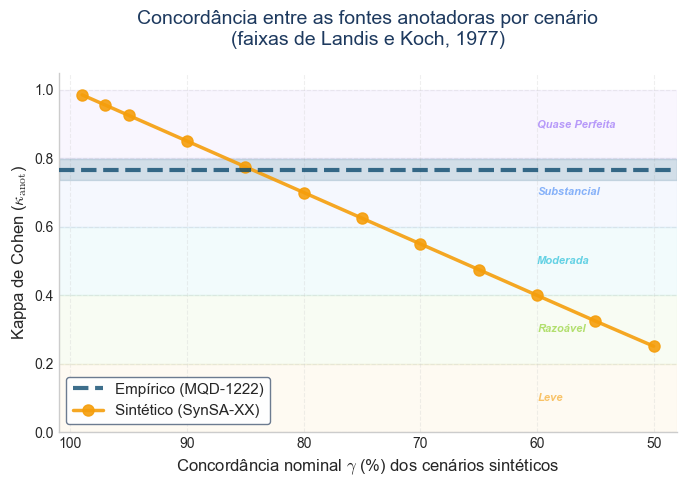


[OK] Gráfico I.1 salvo: comparacao-baselines.png


In [8]:
# ============================================================================
# GRÁFICO I.1 — Baseline: Empírico vs Sintéticos
# ============================================================================

fig, ax = plt.subplots(figsize=(7, 5))

# Baseline empírico (linha horizontal de referência)
ax.axhline(y=kappa_anot_empirico, color=COR_EMPIRICO, linestyle='--',
           linewidth=3, alpha=0.8, label='Empírico (MQD-1222)', zorder=5)

# IC95% do empírico (área sombreada)
ax.axhspan(ic_lower_empirico, ic_upper_empirico, alpha=0.15, color=COR_EMPIRICO, zorder=1)

# Baselines sintéticos (curva)
x_sintetico = [int(ds.split('-')[1]) for ds in baselines_sintetico['Dataset']]
y_sintetico = baselines_sintetico['κ_anot'].values

ax.plot(x_sintetico, y_sintetico, marker='o', linewidth=2.5, markersize=8,
        color=COR_SINTETICO, label='Sintético (SynSA-XX)', alpha=0.9, zorder=3)

# Faixas de Landis & Koch (1977) — valores originais do artigo
# Poor: < 0.00 | Slight: 0.00–0.20 | Fair: 0.21–0.40
# Moderate: 0.41–0.60 | Substantial: 0.61–0.80 | Almost Perfect: 0.81–1.00
faixas = [
    ('Leve', 0.0, 0.20, '#F59E0B'),
    ('Razoável', 0.20, 0.40, '#84CC16'),
    ('Moderada', 0.40, 0.60, '#06B6D4'),
    ('Substancial', 0.60, 0.80, '#3B82F6'),
    ('Quase Perfeita', 0.80, 1.00, '#8B5CF6')
]

for nome, y_low, y_high, cor in faixas:
    ax.axhspan(y_low, y_high, alpha=0.05, color=cor, zorder=0)
    y_mid = (y_low + y_high) / 2
    ax.text(60, y_mid, nome, fontsize=8, alpha=0.6, style='italic',
            verticalalignment='center', horizontalalignment='left',
            color=cor, fontweight='bold')

ax.set_xlabel('Concordância nominal $\gamma$ (%) dos cenários sintéticos',
              fontsize=12, fontweight='regular')
ax.set_ylabel("Kappa de Cohen ($\kappa_{\mathrm{anot}}$)", fontsize=12, fontweight='regular')
#ax.set_ylabel(k_anot)
ax.set_title("Concordância entre as fontes anotadoras por cenário\n"
            "(faixas de Landis e Koch, 1977)",
             fontsize=14, fontweight='regular', color=NATURE_ACCENT, pad=20)

ax.legend(loc='lower left', fontsize=11, frameon=True,
          facecolor='white', edgecolor=NATURE_GRAY, framealpha=0.95)

ax.set_xlim(101, 48)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'comparacao-baselines.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[OK] Gráfico I.1 salvo: comparacao-baselines.png")

## MÓDULO II: Comparação de Modelos Pareados

Comparação das concordâncias entre modelos (κ_pred) nas duas fases:
- **Fase 2**: Concordância entre predições de modelos M/F treinados com dados empíricos
- **Fase 3**: Concordância entre predições de modelos M/F em datasets sintéticos

In [9]:
# ============================================================================
# TABELA II.1 — κ_pred: Empírico vs Sintéticos (por classificador)
# ============================================================================

print("\n" + "="*80)
print("MÓDULO II: COMPARAÇÃO DE MODELOS PAREADOS")
print("="*80)

# Extrair κ_pred empírico
kappa_pred_empirico = metricas_empirico[['modelo', 'kappa_mean']].copy()
kappa_pred_empirico.columns = ['Modelo', 'κ_pred_empirico']

# Extrair κ_pred sintético (média de todos os datasets)
modelos = ['SVM', 'NB', 'RF', 'LR']
kappa_pred_sintetico_df = pd.DataFrame([
    {'Modelo': m, 'κ_pred_sintetico_media': kappa_sintetico[f'{m} κ'].mean()}
    for m in modelos
])

# Merge
tabela_modelos = kappa_pred_empirico.merge(kappa_pred_sintetico_df, on='Modelo')

print("\nTabela II.1 — Concordância intermodelos (κ_pred) por Classificador")
print("-"*80)
print(tabela_modelos.to_string(index=False, float_format='{:.4f}'.format))

# Salvar
tabela_modelos.to_csv(RESULTS_UNIFICADO_DIR / 'kappa-pred-comparado.csv', index=False)
print(f"\n[OK] Tabela salva: kappa-pred-comparado.csv")


MÓDULO II: COMPARAÇÃO DE MODELOS PAREADOS

Tabela II.1 — Concordância intermodelos (κ_pred) por Classificador
--------------------------------------------------------------------------------
Modelo  κ_pred_empirico  κ_pred_sintetico_media
   SVM           0.4945                  0.4418
    NB           0.4755                  0.4502
    RF           0.4526                  0.1772
    LR           0.5191                  0.4575

[OK] Tabela salva: kappa-pred-comparado.csv


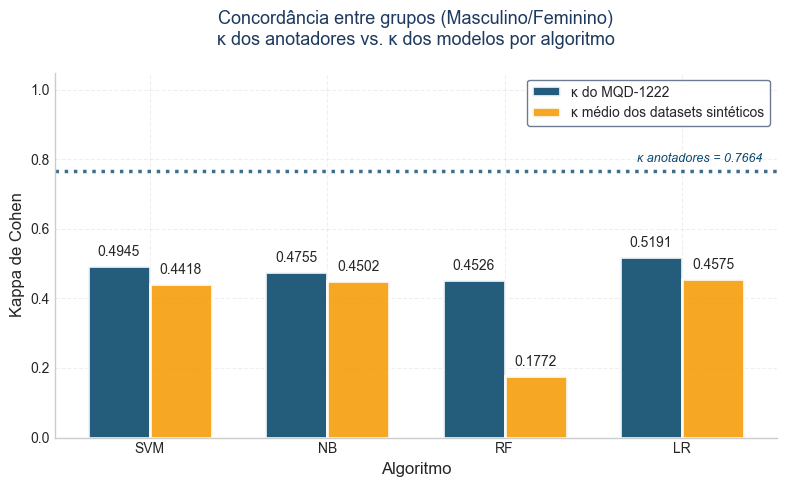


[OK] Gráfico II.1 salvo: kappa-pred-comparado.png


In [10]:
# ============================================================================
# GRÁFICO II.1 — κ_pred: Empírico vs Sintéticos (barras agrupadas)
# ============================================================================

fig, ax = plt.subplots(figsize=(8, 5))  # ligeiramente mais largo para acomodar rótulo inline

x = np.arange(len(modelos))
width = 0.35

bars1 = ax.bar(x - width/2, tabela_modelos['κ_pred_empirico'], width,
               label='κ do MQD-1222', color=COR_EMPIRICO, alpha=0.9,
               edgecolor='white', linewidth=2)
               #,
               #hatch='///')  # hachura para legibilidade em impressão P&B

bars2 = ax.bar(x + width/2, tabela_modelos['κ_pred_sintetico_media'], width,
               label='κ médio dos datasets sintéticos', color=COR_SINTETICO, alpha=0.9,
               edgecolor='white', linewidth=2)
               # sem hachura: diferencia das barras empíricas em P&B

# Linha de κ_anot empírico como referência — mais visível
ax.axhline(y=kappa_anot_empirico, color=COR_EMPIRICO, linestyle=':',
           linewidth=2.5, alpha=0.8)  # removido da legenda; será rotulado inline

# Rótulo direto na linha de referência (elimina dependência da legenda)
ax.text(len(modelos) - 0.55,                     # próximo à extremidade direita
        kappa_anot_empirico + 0.025,
        f'κ anotadores = {kappa_anot_empirico:.4f}',
        fontsize=9, color=COR_EMPIRICO, fontstyle='italic', ha='right')

# Anotações numéricas sobre as barras
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.4f}', ha='center', va='bottom',
                fontsize=10, fontweight='regular')

# Asterisco sobre o outlier RF/sintético com nota explicativa
rf_idx = list(modelos).index('RF')
rf_sintetico_height = tabela_modelos['κ_pred_sintetico_media'][rf_idx]
#ax.text(rf_idx + width/2, rf_sintetico_height + 0.055,   # acima do valor já anotado
#        '*', ha='center', va='bottom', fontsize=14, color='black')

# Nota de rodapé do asterisco (canto inferior esquerdo, fora da área de dados)
#ax.text(0.01, 0.02,
 #       '* RF/sintético: alta variância entre réplicas sintéticas (ver Seção VI.x)',
 #       transform=ax.transAxes, fontsize=8, color='dimgray', fontstyle='italic')

ax.set_xlabel('Algoritmo', fontsize=12, fontweight='regular')
ax.set_ylabel('Kappa de Cohen', fontsize=12, fontweight='regular')

# Título simplificado — M/F expandido, subtítulo redundante removido
ax.set_title('Concordância entre grupos (Masculino/Feminino)\n'
             'κ dos anotadores vs. κ dos modelos por algoritmo',
             fontsize=13, fontweight='regular', color=NATURE_ACCENT, pad=20)

ax.set_xticks(x)
ax.set_xticklabels(modelos)

# Legenda sem a linha de referência (agora rotulada inline)
ax.legend(loc='upper right', fontsize=10, frameon=True,
          facecolor='white', edgecolor=NATURE_GRAY, framealpha=0.95)

ax.set_ylim(0, 1.05)  # margem superior aumentada para acomodar asterisco e rótulos altos
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'kappa-pred-comparado.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n[OK] Gráfico II.1 salvo: kappa-pred-comparado.png")

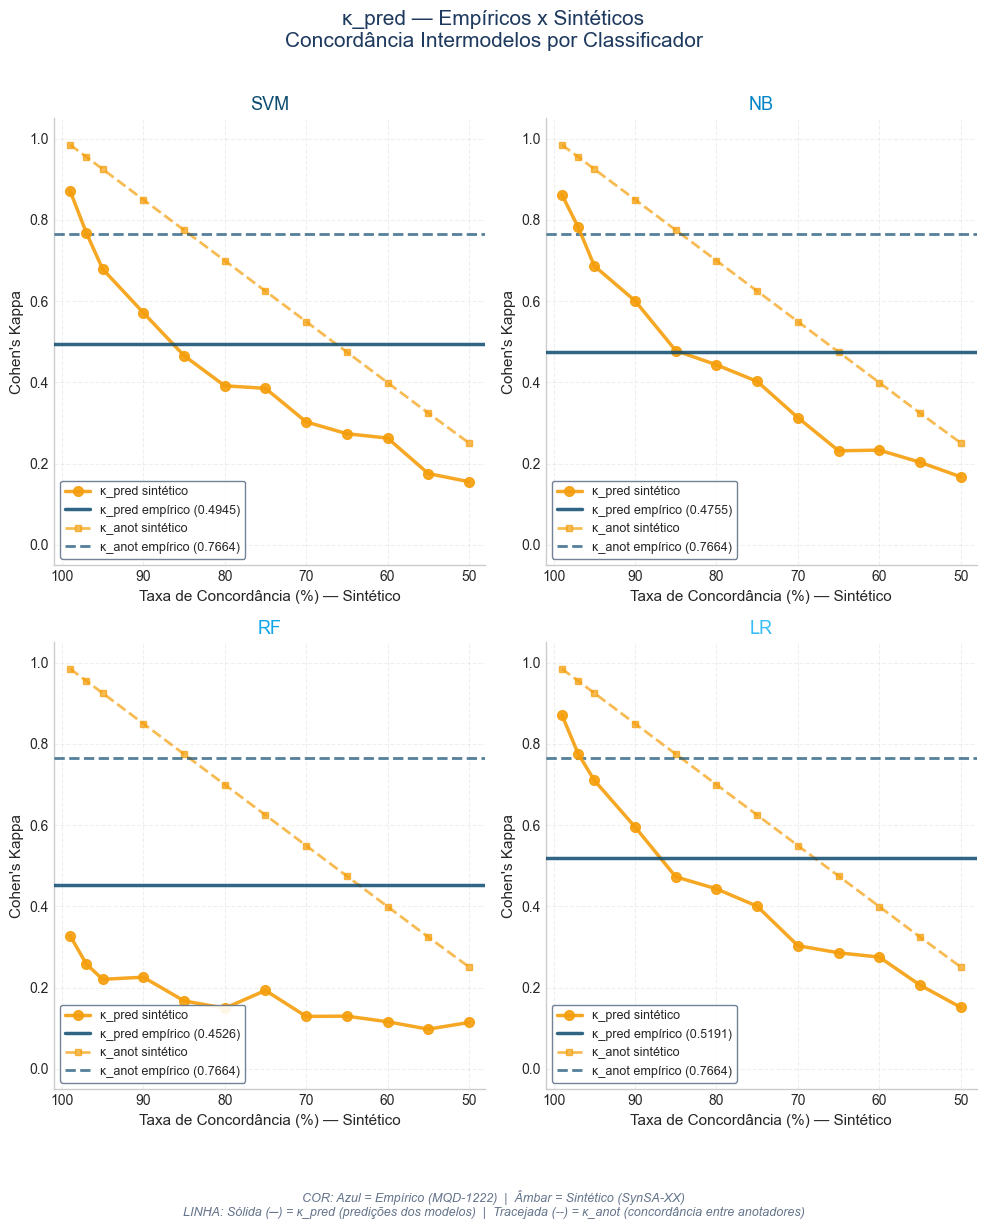


[OK] Gráfico II.2 salvo: kappa-pred-sobrepostos.png


In [11]:

# ============================================================================
# GRÁFICO II.2 — κ_pred: Empírico sobreposto aos Sintéticos (curvas)
# ============================================================================
# Convenção visual:
#   COR   → fase: Azul escuro = Empírico | Âmbar = Sintético
#   LINHA → tipo: Sólida = κ_pred (predições) | Tracejada = κ_anot (anotadores)

fig, axes = plt.subplots(2, 2, figsize=(10, 12))
axes = axes.flatten()

x_sintetico = [int(ds.split('-')[1]) for ds in kappa_sintetico['Dataset']]
y_kin_sin = baselines_sintetico['κ_anot'].values

for idx, modelo in enumerate(modelos):
    ax = axes[idx]

    # --- κ_pred sintético: âmbar, sólida, círculos ---
    y_kmod_sin = kappa_sintetico[f'{modelo} κ'].values
    ax.plot(x_sintetico, y_kmod_sin,
            color=COR_SINTETICO, linestyle='-', linewidth=2.5,
            marker='o', markersize=7, alpha=0.9,
            label='κ_pred sintético', zorder=4)

    # --- κ_pred empírico: azul, sólida, linha horizontal ---
    kappa_modelo_empirico = metricas_empirico[
        metricas_empirico['modelo'] == modelo]['kappa_mean'].values[0]
    ax.axhline(y=kappa_modelo_empirico,
               color=COR_EMPIRICO, linestyle='-', linewidth=2.5, alpha=0.85,
               label=f'κ_pred empírico ({kappa_modelo_empirico:.4f})', zorder=5)

    # --- κ_anot sintético: âmbar, tracejada, quadrados ---
    ax.plot(x_sintetico, y_kin_sin,
            color=COR_SINTETICO, linestyle='--', linewidth=2,
            marker='s', markersize=5, alpha=0.7,
            label='κ_anot sintético', zorder=2)

    # --- κ_anot empírico: azul, tracejada, linha horizontal ---
    ax.axhline(y=kappa_anot_empirico,
               color=COR_EMPIRICO, linestyle='--', linewidth=2, alpha=0.7,
               label=f'κ_anot empírico ({kappa_anot_empirico:.4f})', zorder=3)

    ax.set_xlabel('Taxa de Concordância (%) — Sintético', fontsize=11, fontweight='regular')
    ax.set_ylabel("Cohen's Kappa", fontsize=11, fontweight='regular')
    ax.set_title(f'{modelo}', fontsize=13, fontweight='regular',
                 color=CORES_MODELOS_NATURE[modelo])
    ax.legend(loc='lower left', fontsize=9, frameon=True,
              facecolor='white', edgecolor=NATURE_GRAY, framealpha=0.9)
    ax.set_xlim(101, 48)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.3, linestyle='--')

# Nota de rodapé com a convenção dupla
fig.text(0.5, -0.01,
         "COR: Azul = Empírico (MQD-1222)  |  Âmbar = Sintético (SynSA-XX)\n"
         "LINHA: Sólida (─) = κ_pred (predições dos modelos)  |  "
         "Tracejada (--) = κ_anot (concordância entre anotadores)",
         ha='center', fontsize=9, style='italic', color=NATURE_GRAY)

plt.suptitle("κ_pred — Empíricos x Sintéticos\n"
             "Concordância Intermodelos por Classificador",
             fontsize=15, fontweight='regular', color=NATURE_ACCENT, y=0.995)
plt.tight_layout(rect=[0, 0.05, 1, 0.985])
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'kappa-pred-sobrepostos.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n[OK] Gráfico II.2 salvo: kappa-pred-sobrepostos.png")

## MÓDULO III: Análise de Amplificação (Δκ)

**Núcleo da metodologia MADA**: Comparação do Delta Kappa (Δκ = κ_anot - κ_pred) entre fases.

**Critério de Severidade**: Baseado em **Landis & Koch (1977)**, pela queda de faixas de concordância.

In [12]:
# ============================================================================
# TABELA III.1 — Delta Kappa e Severidade: Empírico vs Sintéticos
# ============================================================================

print("\n" + "="*80)
print("MÓDULO III: ANÁLISE DE AMPLIFICAÇÃO (Δκ)")
print("="*80)

# Extrair Δκ empírico
delta_empirico_tbl = divergencia_empirico[['modelo', 'delta_kappa', 'severidade', 'faixas_perdidas']].copy()
delta_empirico_tbl.columns = ['Modelo', 'Δκ_empirico', 'Severidade_empirico', 'Faixas_empirico']

# Extrair Δκ sintético (média de todos os datasets)
delta_sintetico_media = []
for modelo in modelos:
    col_dk = f'{modelo} Δκ'
    col_sev = f'{modelo} Sev'
    col_fx = f'{modelo} Faixas'

    sev_mode = delta_sintetico[col_sev].mode()
    delta_sintetico_media.append({
        'Modelo': modelo,
        'Δκ_sintetico_media': delta_sintetico[col_dk].mean(),
        'Severidade_sintetico_modal': sev_mode.iloc[0] if len(sev_mode) > 0 else 'Nulo',
        'Faixas_sintetico_media': delta_sintetico[col_fx].mean()
    })

delta_sintetico_tbl = pd.DataFrame(delta_sintetico_media)

# Merge
tabela_delta = delta_empirico_tbl.merge(delta_sintetico_tbl, on='Modelo')

print("\nTabela III.1 — Delta Kappa (Δκ) e Severidade: Empírico vs Sintético")
print("-"*80)
print(tabela_delta.to_string(index=False))

# Salvar
tabela_delta.to_csv(RESULTS_UNIFICADO_DIR / 'delta-kappa-comparado.csv', index=False)
print(f"\n[OK] Tabela salva: delta-kappa-comparado.csv")


MÓDULO III: ANÁLISE DE AMPLIFICAÇÃO (Δκ)

Tabela III.1 — Delta Kappa (Δκ) e Severidade: Empírico vs Sintético
--------------------------------------------------------------------------------
Modelo  Δκ_empirico Severidade_empirico  Faixas_empirico  Δκ_sintetico_media Severidade_sintetico_modal  Faixas_sintetico_media
   SVM       0.2719            Restrito                1              0.2092                   Restrito                  1.0833
    NB       0.2909            Restrito                1              0.2008                   Restrito                  0.7500
    RF       0.3138            Restrito                1              0.4738                  Acentuado                  2.3333
    LR       0.2473            Restrito                1              0.1935                   Restrito                  0.8333

[OK] Tabela salva: delta-kappa-comparado.csv


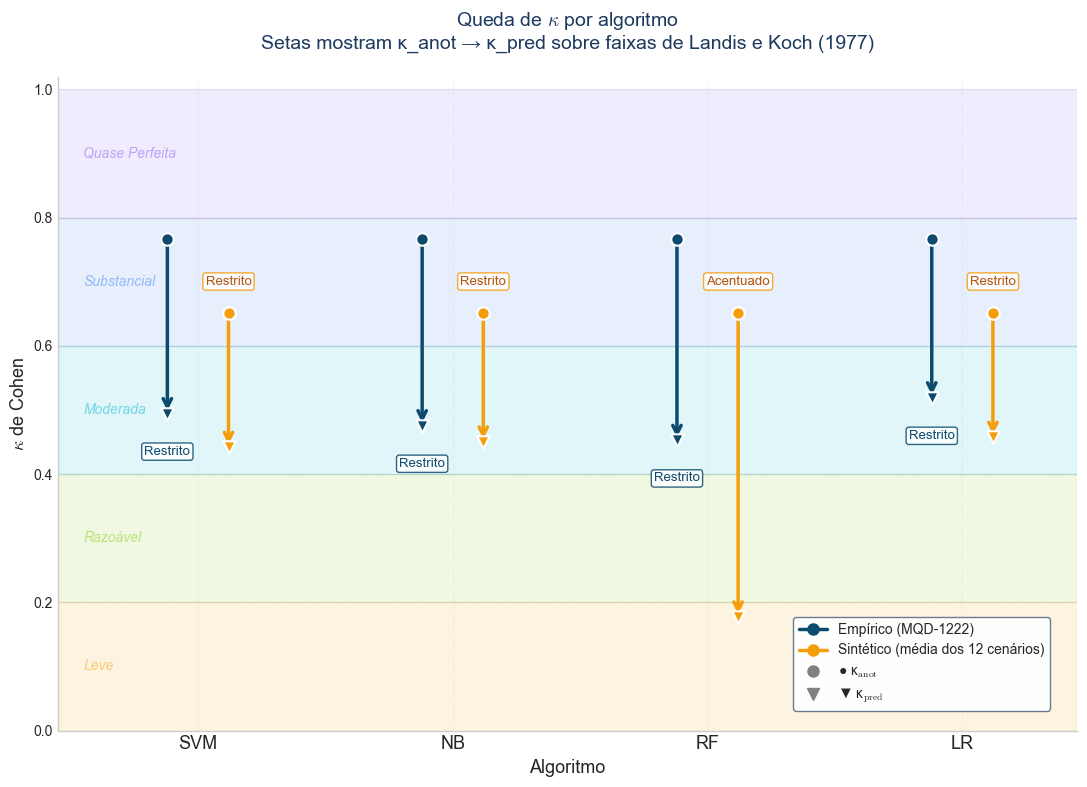


[OK] Gráfico III.1 salvo: delta-kappa-comparado.png


In [13]:
# ============================================================================
# GRÁFICO III.1 — Amplificação de Viés: Dumbbell Chart com Faixas L&K
# ============================================================================
# Cada seta mostra a queda de κ_anot → κ_pred.
# As faixas de Landis & Koch (1977) como fundo tornam a severidade auto-evidente:
# a quantidade de faixas coloridas que a seta atravessa = severidade.

fig, ax = plt.subplots(figsize=(11, 8))

# --- Faixas de Landis & Koch como fundo ---
faixas_lk = [
    ('Leve',          0.00, 0.20, '#F59E0B'),
    ('Razoável',            0.20, 0.40, '#84CC16'),
    ('Moderada',        0.40, 0.60, '#06B6D4'),
    ('Substancial',     0.60, 0.80, '#3B82F6'),
    ('Quase Perfeita',  0.80, 1.00, '#8B5CF6'),
]

for nome, y_low, y_high, cor in faixas_lk:
    ax.axhspan(y_low, y_high, alpha=0.12, color=cor, zorder=0)
    y_mid = (y_low + y_high) / 2
    ax.text(-0.45, y_mid, nome, fontsize=10, alpha=0.5,
            style='italic', va='center', ha='left', color=cor, fontweight='regular')

for _, y_low, y_high, _ in faixas_lk:
    ax.axhline(y=y_low, color='gray', linestyle=':', linewidth=0.7, alpha=0.4, zorder=1)


def desenhar_seta(ax, x, k_ini, k_mod, dk, sev, cor, label_va, label_offset):
    """Desenha seta κ_anot → κ_pred com rótulo de Δκ."""
    ax.annotate('', xy=(x, k_mod), xytext=(x, k_ini),
                arrowprops=dict(arrowstyle='->', color=cor, lw=2.5, mutation_scale=15),
                zorder=5)
    ax.scatter(x, k_ini, color=cor, s=80, zorder=6,
               edgecolors='white', linewidths=1.5, marker='o')
    ax.scatter(x, k_mod, color=cor, s=80, zorder=6,
               edgecolors='white', linewidths=1.5, marker='v')

    cor_texto = '#B45309' if cor == COR_SINTETICO else cor
    ax.text(x, label_offset,
            #f'Δκ={dk:+.2f} ({sev})',
            f'{sev}',
            fontsize=9.5, ha='center', va=label_va, color=cor_texto,
            fontweight='regular', bbox=dict(boxstyle='round,pad=0.2',
            facecolor='white', edgecolor=cor, alpha=0.85))


# --- Dados ---
x_positions = np.arange(len(modelos))
offset = 0.12

for idx, modelo in enumerate(modelos):
    row = tabela_delta[tabela_delta['Modelo'] == modelo].iloc[0]

    # Empírico
    k_ini_emp = kappa_anot_empirico
    k_mod_emp = metricas_empirico[metricas_empirico['modelo'] == modelo]['kappa_mean'].values[0]
    desenhar_seta(ax, idx - offset, k_ini_emp, k_mod_emp,
                  row['Δκ_empirico'], row['Severidade_empirico'],
                  COR_EMPIRICO, 'top', k_mod_emp - 0.05)

    # Sintético (média)
    k_ini_sin = baselines_sintetico['κ_anot'].mean()
    k_mod_sin = kappa_sintetico[f'{modelo} κ'].mean()
    desenhar_seta(ax, idx + offset, k_ini_sin, k_mod_sin,
                  row['Δκ_sintetico_media'], row['Severidade_sintetico_modal'],
                  COR_SINTETICO, 'bottom', k_ini_sin + 0.04)

# --- Legenda manual ---
legend_elements = [
    Line2D([0], [0], color=COR_EMPIRICO, lw=2.5, marker='o', markersize=8,
           label='Empírico (MQD-1222)', markerfacecolor=COR_EMPIRICO),
    Line2D([0], [0], color=COR_SINTETICO, lw=2.5, marker='o', markersize=8,
           label='Sintético (média dos 12 cenários)', markerfacecolor=COR_SINTETICO),
    Line2D([0], [0], color='gray', lw=0, marker='o', markersize=8,
           label=f'● {K_ANOT}', markerfacecolor='gray'),
    Line2D([0], [0], color='gray', lw=0, marker='v', markersize=8,
           label=f'▼ {K_PRED}', markerfacecolor='gray'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10, frameon=True,
          facecolor='white', edgecolor=NATURE_GRAY, framealpha=0.95,
          bbox_to_anchor=(0.98, 0.02))

# --- Eixos ---
ax.set_xticks(x_positions)
ax.set_xticklabels(modelos, fontsize=13, fontweight='regular')
ax.set_xlabel('Algoritmo', fontsize=13, fontweight='regular')
ax.set_ylabel(r'$\kappa$ de Cohen', fontsize=13, fontweight='regular')
ax.set_title("Queda de $\\kappa$ por algoritmo\n"
             "Setas mostram κ_anot → κ_pred sobre faixas de Landis e Koch (1977)",
             fontsize=14, fontweight='regular', color=NATURE_ACCENT, pad=20)

ax.set_xlim(-0.55, len(modelos) - 0.55)
ax.set_ylim(0, 1.02)
ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'delta-kappa-comparado.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n[OK] Gráfico III.1 salvo: delta-kappa-comparado.png")

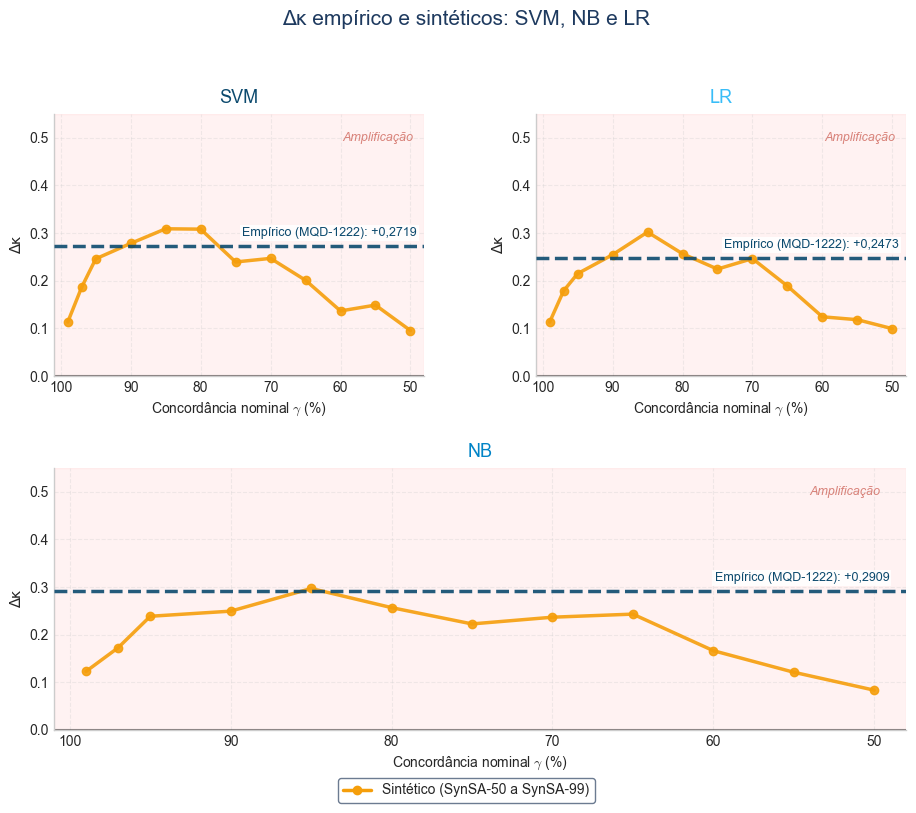


[OK] Gráfico III.2a salvo: delta-kappa-svm-nb-lr.png


In [14]:
# ============================================================================
# GRÁFICO III.2a — Δκ: SVM, NB e LR (grid 2+1 com GridSpec)
# ============================================================================
import matplotlib.gridspec as gridspec

modelos_principais = ['SVM', 'NB', 'LR']

YLIM_PRINCIPAL = (0.0, 0.55)

fig = plt.figure(figsize=(11, 8))
gs = gridspec.GridSpec(2, 2, figure=fig,
                       hspace=0.35, wspace=0.3)

# Posições: SVM=linha0/col0, LR=linha0/col1, NB=linha1 centralizado
pos = [gs[0, 0], gs[1, 0:2], gs[0, 1]]   # NB ocupa as duas colunas da linha inferior — centralizado e mais largo

for idx, modelo in enumerate(modelos_principais):
    ax = fig.add_subplot(pos[idx])

    col_dk = f'{modelo} Δκ'
    x_sintetico = [int(ds.split('-')[1]) for ds in delta_sintetico['Dataset']]
    y_delta_sintetico = delta_sintetico[col_dk].values

    # Fundo de amplificação
    ax.axhspan(0, YLIM_PRINCIPAL[1], alpha=0.05, color='red', zorder=0)

    # Curva sintética
    ax.plot(x_sintetico, y_delta_sintetico,
            marker='o', linewidth=2.5, markersize=6,
            color=COR_SINTETICO, alpha=0.9, zorder=3)

    # Linha empírica
    delta_empirico_val = divergencia_empirico[
        divergencia_empirico['modelo'] == modelo
    ]['delta_kappa'].values[0]

    ax.axhline(y=delta_empirico_val, color=COR_EMPIRICO,
               linestyle='--', linewidth=2.5, alpha=0.9, zorder=5)

    # Rótulo inline da linha empírica
    ax.text(0.98, delta_empirico_val + 0.015,
            f'Empírico (MQD-1222): {delta_empirico_val:+.4f}'.replace(".", ","),
            transform=ax.get_yaxis_transform(),
            fontsize=9, color=COR_EMPIRICO,
            fontweight='regular', va='bottom', ha='right',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))

    # Linha de referência Δκ = 0
    ax.axhline(y=0, color='black', linestyle='-',
               linewidth=1.5, alpha=0.5, zorder=1)

    # Rótulo "Amplificação"
    ax.text(0.97, 0.93, 'Amplificação',
            transform=ax.transAxes,
            fontsize=9, color='#C0392B', fontstyle='italic',
            fontweight='regular', ha='right', va='top', alpha=0.6)

    # Título do painel
    ax.set_title(modelo, fontsize=13, fontweight='regular',
                 color=CORES_MODELOS_NATURE[modelo], pad=8)

    ax.set_ylabel('Δκ', fontsize=11, fontweight='regular')
    ax.set_xlabel('Concordância nominal $\gamma$ (%)',
                  fontsize=10, fontweight='regular')
    ax.set_xlim(101, 48)
    ax.set_ylim(YLIM_PRINCIPAL)
    ax.grid(True, alpha=0.3, linestyle='--')

# Legenda única centralizada
handles = [
    plt.Line2D([0], [0], color=COR_SINTETICO, marker='o',
               linewidth=2.5, markersize=6, label='Sintético (SynSA-50 a SynSA-99)'),
]
fig.legend(handles=handles, loc='lower center', ncol=1,
           fontsize=10, frameon=True, facecolor='white',
           edgecolor=NATURE_GRAY, framealpha=0.95,
           bbox_to_anchor=(0.5, 0.01))

plt.suptitle(f'{DK} empírico e sintéticos: SVM, NB e LR',
             fontsize=15, fontweight='regular', color=NATURE_ACCENT, y=1.01)

#fig.text(0.5, -0.03,
         
#         "SVM e LR: valores empíricos contidos nas curvas (~80–85% e ~80–90% de concordância, respectivamente). "
#         "NB (0,2984): supera o teto da curva (0,2968 em SynSA-85) por margem mínima.",
#         ha='center', fontsize=9, fontstyle='italic', color=NATURE_GRAY)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'delta-kappa-svm-nb-lr.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("\n[OK] Gráfico III.2a salvo: delta-kappa-svm-nb-lr.png")

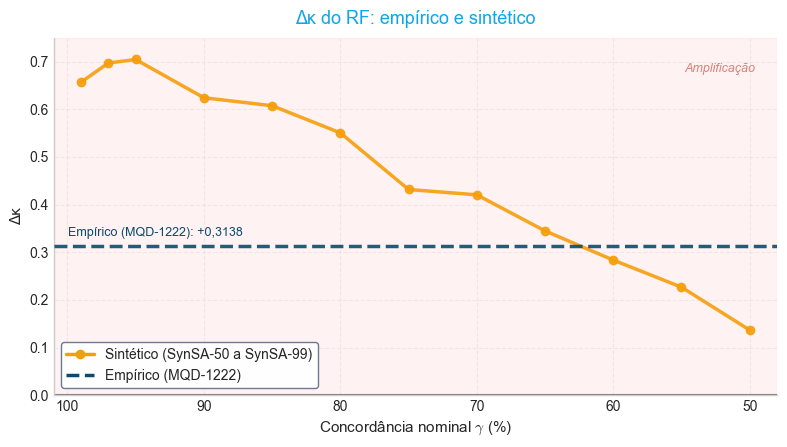


[OK] Gráfico III.2b salvo: delta-kappa-rf-singular.png


In [15]:
# ============================================================================
# GRÁFICO III.2b — Δκ: RF isolado (perfil singular)
# ============================================================================

fig, ax = plt.subplots(figsize=(8, 5))

modelo = 'RF'
col_dk = f'{modelo} Δκ'
x_sintetico = [int(ds.split('-')[1]) for ds in delta_sintetico['Dataset']]
y_delta_sintetico = delta_sintetico[col_dk].values

delta_empirico_val = divergencia_empirico[
    divergencia_empirico['modelo'] == modelo
]['delta_kappa'].values[0]

# Fundo de amplificação
ax.axhspan(0, 0.75, alpha=0.05, color='red', zorder=0)

# Curva sintética
ax.plot(x_sintetico, y_delta_sintetico,
        marker='o', linewidth=2.5, markersize=6,
        color=COR_SINTETICO, alpha=0.9, zorder=3)

# Linha empírica
ax.axhline(y=delta_empirico_val, color=COR_EMPIRICO,
           linestyle='--', linewidth=2.5, alpha=0.9, zorder=5)

# Rótulo inline da linha empírica
ax.text(0.02, delta_empirico_val + 0.015,
        f'Empírico (MQD-1222): {delta_empirico_val:+.4f}'.replace(".", ","),
        transform=ax.get_yaxis_transform(),
        fontsize=9, color=COR_EMPIRICO,
        fontweight='regular', va='bottom')

# Linha de referência Δκ = 0
ax.axhline(y=0, color='black', linestyle='-',
           linewidth=1.5, alpha=0.5, zorder=1)

# Rótulo "Amplificação"
ax.text(0.97, 0.93, 'Amplificação',
        transform=ax.transAxes,
        fontsize=9, color='#C0392B', fontstyle='italic',
        fontweight='regular', ha='right', va='top', alpha=0.6)

# Anotação do perfil singular — diferencia este gráfico do anterior
""" ax.annotate('Curva sintética sistematicamente\nacima do valor empírico\nem toda a faixa testada',
            xy=(95, y_delta_sintetico[0]),        # aponta para o pico da curva
            xytext=(75, 0.62),
            fontsize=8.5, color='dimgray', fontstyle='italic',
            arrowprops=dict(arrowstyle='->', color='dimgray', lw=1.2)) """

ax.set_title(f'{DK} do RF: empírico e sintético',
             fontsize=13, fontweight='regular',
             color=CORES_MODELOS_NATURE[modelo], pad=10)

ax.set_xlabel('Concordância nominal $\gamma$ (%)',
              fontsize=11, fontweight='regular')
ax.set_ylabel('Δκ', fontsize=11, fontweight='regular')
ax.set_xlim(101, 48)
ax.set_ylim(0.0, 0.75)
ax.grid(True, alpha=0.3, linestyle='--')

# Legenda
handles = [
    plt.Line2D([0], [0], color=COR_SINTETICO, marker='o',
               linewidth=2.5, markersize=6, label='Sintético (SynSA-50 a SynSA-99)'),
    plt.Line2D([0], [0], color=COR_EMPIRICO, linestyle='--',
               linewidth=2.5, label='Empírico (MQD-1222)')
]
ax.legend(handles=handles, loc='lower left', fontsize=10,
          frameon=True, facecolor='white',
          edgecolor=NATURE_GRAY, framealpha=0.95)

##fig.text(0.5, -0.04,
#         "Linha tracejada: Δκ empírico (MQD-1222). Curva laranja: Δκ sintético (SynSA-50 a SynSA-99). "
#         "Fundo vermelho: região de amplificação (Δκ > 0).\n",

#         ha='center', fontsize=9, fontstyle='italic', color=NATURE_GRAY)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(GRAFICOS_UNIFICADO_DIR / 'delta-kappa-rf-singular.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("\n[OK] Gráfico III.2b salvo: delta-kappa-rf-singular.png")

## MÓDULO IV: Conclusões e Interpretação Acadêmica

Síntese dos resultados unificados e validação da hipótese de amplificação de viés.

In [16]:
# ============================================================================
# ANÁLISE ESTATÍSTICA CONSOLIDADA
# ============================================================================

print("\n" + "="*80)
print("MÓDULO IV: CONCLUSÕES E INTERPRETAÇÃO ACADÊMICA")
print("="*80)

print("\n" + "-"*80)
print("RESUMO QUANTITATIVO")
print("-"*80)

# Estatísticas descritivas
print("\n[Baseline]")
print(f"  Empírico: κ_anot = {kappa_anot_empirico:.4f} (Substantial)")
print(f"  Sintético: κ_anot varia de {baselines_sintetico['κ_anot'].min():.4f} a {baselines_sintetico['κ_anot'].max():.4f}")

kappa_cols = [f'{m} κ' for m in modelos]

print("\n[Modelos Pareados]")
print(f"  Empírico: κ_pred médio = {metricas_empirico['kappa_mean'].mean():.4f}")
print(f"  Sintético: κ_pred médio global = {kappa_sintetico[kappa_cols].values.mean():.4f}")

print("\n[Amplificação de Viés]")
n_amplifica = divergencia_empirico['amplificacao_detectada'].sum()
n_total_emp = len(divergencia_empirico)
print(f"  Empírico: {n_amplifica}/{n_total_emp} modelos ({n_amplifica/n_total_emp*100:.0f}%) apresentam amplificação")
print(f"  Empírico: Δκ médio = {divergencia_empirico['delta_kappa'].mean():+.4f}")
print(f"  Empírico: Severidade predominante = {divergencia_empirico['severidade'].mode()[0]} (descrição por faixas, não teste inferencial)")

# Contagem de amplificações no sintético
faixas_cols = [f'{m} Faixas' for m in modelos]
amplificacoes_sintetico = sum((delta_sintetico[f'{m} Δκ'] > 0).sum() for m in modelos)
total_sintetico = len(delta_sintetico) * len(modelos)

print(f"\n  Sintético: {amplificacoes_sintetico}/{total_sintetico} pares dataset-modelo ({amplificacoes_sintetico/total_sintetico*100:.1f}%) apresentam amplificação")

delta_cols = [f'{m} Δκ' for m in modelos]
print(f"  Sintético: Δκ médio global = {delta_sintetico[delta_cols].values.mean():+.4f}")

# Ranking de modelos
print("\n[Ranking de Modelos]")
print("  Por Δκ médio (do menos ao mais amplificador):")

rank_empirico = divergencia_empirico.sort_values('delta_kappa')[['modelo', 'delta_kappa']]
rank_sintetico = tabela_delta.sort_values('Δκ_sintetico_media')[['Modelo', 'Δκ_sintetico_media']]

print("\n  Empírico:")
for _, row in rank_empirico.iterrows():
    print(f"    {row['modelo']}: Δκ = {row['delta_kappa']:+.4f}")

print("\n  Sintético (média):")
for _, row in rank_sintetico.iterrows():
    print(f"    {row['Modelo']}: Δκ = {row['Δκ_sintetico_media']:+.4f}")


MÓDULO IV: CONCLUSÕES E INTERPRETAÇÃO ACADÊMICA

--------------------------------------------------------------------------------
RESUMO QUANTITATIVO
--------------------------------------------------------------------------------

[Baseline]
  Empírico: κ_anot = 0.7664 (Substantial)
  Sintético: κ_anot varia de 0.2507 a 0.9850

[Modelos Pareados]
  Empírico: κ_pred médio = 0.4854
  Sintético: κ_pred médio global = 0.3817

[Amplificação de Viés]
  Empírico: 4/4 modelos (100%) apresentam amplificação
  Empírico: Δκ médio = +0.2810
  Empírico: Severidade predominante = Restrito (descrição por faixas, não teste inferencial)

  Sintético: 48/48 pares dataset-modelo (100.0%) apresentam amplificação
  Sintético: Δκ médio global = +0.2693

[Ranking de Modelos]
  Por Δκ médio (do menos ao mais amplificador):

  Empírico:
    LR: Δκ = +0.2473
    SVM: Δκ = +0.2719
    NB: Δκ = +0.2909
    RF: Δκ = +0.3138

  Sintético (média):
    LR: Δκ = +0.1935
    NB: Δκ = +0.2008
    SVM: Δκ = +0.2092
   

In [17]:
# ============================================================================
# EXPORTAÇÃO FINAL — Tabela Consolidada para Publicação
# ============================================================================

# Criar tabela principal unificada (empírico)
tabela_final = pd.DataFrame({
    'Estudo': ['Empírico'] * len(modelos),
    'Dataset': ['MQD-1222'] * len(modelos),
    'Modelo': modelos
})

tabela_final = tabela_final.merge(
    divergencia_empirico[['modelo', 'kappa_anot', 'kappa_pred', 'delta_kappa',
                           'severidade', 'faixas_perdidas', 'amplificacao_detectada']],
    left_on='Modelo', right_on='modelo', how='left'
).drop('modelo', axis=1)

tabela_final.columns = [
    'Estudo', 'Dataset', 'Modelo', 'κ_anot', 'κ_pred', 'Δκ',
    'Severidade', 'Faixas_Perdidas', 'Amplificacao_Detectada'
]

# Adicionar linhas sintéticas (resumo por modelo) — construir lista, depois concat uma vez
linhas_sinteticas = []
for modelo in modelos:
    sev_mode = delta_sintetico[f'{modelo} Sev'].mode()
    faixas_col = delta_sintetico[f'{modelo} Faixas']
    linhas_sinteticas.append({
        'Estudo': 'Sintético (média)',
        'Dataset': 'SynSA-50 a SynSA-99',
        'Modelo': modelo,
        'κ_anot': baselines_sintetico['κ_anot'].mean(),
        'κ_pred': kappa_sintetico[f'{modelo} κ'].mean(),
        'Δκ': delta_sintetico[f'{modelo} Δκ'].mean(),
        'Severidade': sev_mode.iloc[0] if len(sev_mode) > 0 else 'Nulo',
        'Faixas_Perdidas': faixas_col.mean(),
        'Amplificacao_Detectada': (delta_sintetico[f'{modelo} Δκ'] > 0).sum() > len(delta_sintetico) / 2
    })

tabela_final = pd.concat([tabela_final, pd.DataFrame(linhas_sinteticas)], ignore_index=True)

print("\n" + "="*80)
print("TABELA FINAL CONSOLIDADA")
print("="*80)
print(tabela_final.to_string(index=False, float_format='{:.4f}'.format))

# Salvar
tabela_final.to_csv(RESULTS_UNIFICADO_DIR / 'tabela-final-consolidada.csv', index=False)
print(f"\n[OK] Tabela final salva: tabela-final-consolidada.csv")


TABELA FINAL CONSOLIDADA
           Estudo             Dataset Modelo  κ_anot  κ_pred     Δκ Severidade  Faixas_Perdidas  Amplificacao_Detectada
         Empírico            MQD-1222    SVM  0.7664  0.4945 0.2719   Restrito           1.0000                    True
         Empírico            MQD-1222     NB  0.7664  0.4755 0.2909   Restrito           1.0000                    True
         Empírico            MQD-1222     RF  0.7664  0.4526 0.3138   Restrito           1.0000                    True
         Empírico            MQD-1222     LR  0.7664  0.5191 0.2473   Restrito           1.0000                    True
Sintético (média) SynSA-50 a SynSA-99    SVM  0.6510  0.4418 0.2092   Restrito           1.0833                    True
Sintético (média) SynSA-50 a SynSA-99     NB  0.6510  0.4502 0.2008   Restrito           0.7500                    True
Sintético (média) SynSA-50 a SynSA-99     RF  0.6510  0.1772 0.4738  Acentuado           2.3333                    True
Sintético (méd

In [18]:
# ============================================================================
# RESUMO FINAL DE ARQUIVOS GERADOS
# ============================================================================

print("\n" + "="*80)
print("RESUMO DE ARQUIVOS GERADOS")
print("="*80)

print("\nTabelas:")
for f in sorted(RESULTS_UNIFICADO_DIR.iterdir()):
    if f.is_file() and f.suffix == '.csv':
        print(f"  [OK] {f.name}")

print("\nGráficos:")
for f in sorted(GRAFICOS_UNIFICADO_DIR.iterdir()):
    if f.is_file() and f.suffix == '.png':
        print(f"  [OK] {f.name}")

print("\n" + "="*80)
print("[OK] ANÁLISE UNIFICADA MADA CONCLUÍDA COM SUCESSO")
print("="*80)
print('\nNota: a interpretação científica depende dos valores, dos intervalos de confiança')
print('e da auditoria integrada posterior. Nenhuma hipótese é declarada validada automaticamente.')



RESUMO DE ARQUIVOS GERADOS

Tabelas:
  [OK] baselines-comparados.csv
  [OK] delta-kappa-comparado.csv
  [OK] kappa-pred-comparado.csv
  [OK] tabela-final-consolidada.csv

Gráficos:
  [OK] comparacao-baselines.png
  [OK] delta-kappa-comparado.png
  [OK] delta-kappa-rf-singular.png
  [OK] delta-kappa-svm-nb-lr.png
  [OK] kappa-pred-comparado.png
  [OK] kappa-pred-sobrepostos.png

[OK] ANÁLISE UNIFICADA MADA CONCLUÍDA COM SUCESSO

Nota: a interpretação científica depende dos valores, dos intervalos de confiança
e da auditoria integrada posterior. Nenhuma hipótese é declarada validada automaticamente.


In [19]:
from datetime import datetime
from IPython.display import Markdown, display
import pandas as pd

def fmt_num(valor):
    return f"{valor:.4f}".replace('.', ',')

def fmt_delta(valor):
    return f"{valor:+.4f}".replace('.', ',')

def fmt_pct(valor):
    return f"{valor:.1f}".replace('.', ',')

def fmt_int_br(valor):
    return f"{int(valor):,}".replace(',', '.')

def lk_label(kappa):
    if kappa < 0.00:
        return "Poor"
    if kappa <= 0.20:
        return "Slight"
    if kappa <= 0.40:
        return "Fair"
    if kappa <= 0.60:
        return "Moderate"
    if kappa <= 0.80:
        return "Substantial"
    return "Almost Perfect"

def listar_modelos(series, formatter=fmt_num):
    return " | ".join(
        f"{modelo} = {formatter(series[modelo])}"
        for modelo in modelos
    )

emp_kpred = metricas_empirico.set_index('modelo')['kappa_mean'].reindex(modelos)
emp_delta = divergencia_empirico.set_index('modelo')['delta_kappa'].reindex(modelos)
emp_faixas = divergencia_empirico.set_index('modelo')['faixas_perdidas'].reindex(modelos)

total_combinacoes = len(delta_sintetico) * len(modelos)
amplificacao_universal = sum((delta_sintetico[f'{modelo} Δκ'] > 0).sum() for modelo in modelos)
quedas_lk = sum((delta_sintetico[f'{modelo} Faixas'] >= 1).sum() for modelo in modelos)

delta_media_sint = pd.Series({
    modelo: delta_sintetico[f'{modelo} Δκ'].mean()
    for modelo in modelos
}).sort_values()

rank_emp = emp_delta.sort_values()

rf_delta = delta_sintetico[['Dataset', 'RF Δκ', 'RF Faixas']].copy()
rf_min = rf_delta.loc[rf_delta['RF Δκ'].idxmin()]
rf_max = rf_delta.loc[rf_delta['RF Δκ'].idxmax()]
rf_severo = int((rf_delta['RF Faixas'] >= 3).sum())

controlados = ['SVM', 'NB', 'LR']
picos_controlados = []
for modelo in controlados:
    serie = delta_sintetico[['Dataset', f'{modelo} Δκ', f'{modelo} Faixas']].copy()
    pico = serie.loc[serie[f'{modelo} Δκ'].idxmax()]
    picos_controlados.append(
        f"{modelo}: pico em {pico['Dataset']} com Δκ = {fmt_delta(pico[f'{modelo} Δκ'])} e {int(pico[f'{modelo} Faixas'])} faixa(s) perdidas"
    )

baselines_ordenados = baselines_sintetico.sort_values('κ_anot').reset_index(drop=True)
idx_ref = (baselines_ordenados['κ_anot'] - kappa_anot_empirico).abs().idxmin()
baseline_ref = baselines_ordenados.loc[idx_ref]
baseline_anterior = baselines_ordenados.loc[max(idx_ref - 1, 0)]
baseline_posterior = baselines_ordenados.loc[min(idx_ref + 1, len(baselines_ordenados) - 1)]

ref_dataset = baseline_ref['Dataset']
ref_row = kappa_sintetico.loc[kappa_sintetico['Dataset'] == ref_dataset].iloc[0]
timestamp_execucao = datetime.now().strftime('%d/%m/%Y %H:%M:%S')

def comparacao_modelo(modelo):
    serie = delta_sintetico[['Dataset', f'{modelo} Δκ']].copy()
    emp = float(emp_delta[modelo])
    minimo = float(serie[f'{modelo} Δκ'].min())
    maximo = float(serie[f'{modelo} Δκ'].max())
    prox = serie.iloc[(serie[f'{modelo} Δκ'] - emp).abs().argmin()]

    if emp > maximo:
        situacao = f"supera o teto sintético ({fmt_delta(maximo)})"
    elif emp < minimo:
        situacao = f"fica abaixo do piso sintético ({fmt_delta(minimo)})"
    else:
        situacao = f"permanece dentro da faixa sintética [{fmt_delta(minimo)}, {fmt_delta(maximo)}]"

    return (
        f"- **{modelo}**: Δκ empírico = {fmt_delta(emp)}; {situacao}; "
        f"aproximação mais próxima em {prox['Dataset']} ({fmt_delta(prox[f'{modelo} Δκ'])})."
    )

signif_path = RESULTS_EMPIRICO_DIR / 'significancia-delta-kappa.csv'
if signif_path.exists():
    df_signif = pd.read_csv(signif_path)
    if 'significativo' in df_signif.columns:
        n_signif = int(df_signif['significativo'].fillna(False).astype(bool).sum())
    else:
        n_signif = None
else:
    n_signif = None

linhas = [
    "### Interpretação Acadêmica Final",
    "",
    f"**Data e hora da execução:** {timestamp_execucao}",
    "",
    "#### 1. Validação da Hipótese de Amplificação",
    "",
    "**Hipótese MADA**: Modelos de classificação treinados com anotações de diferentes grupos *amplificam* as divergências iniciais entre esses grupos, resultando em maior discordância entre predições (κ_pred < κ_anot).",
    "",
    "**Evidências Empíricas (Fase 2 — MQD-1222)**:",
    f"- κ_anot (anotadores humanos) = **{fmt_num(kappa_anot_empirico)}** ({lk_label(kappa_anot_empirico)} — Landis & Koch, 1977), IC 95% = [{fmt_num(ic_lower_empirico)}; {fmt_num(ic_upper_empirico)}]",
    f"- κ_pred por classificador: {listar_modelos(emp_kpred)}",
    f"- κ_pred médio = **{fmt_num(emp_kpred.mean())}** ({lk_label(emp_kpred.mean())})",
    f"- Δκ por classificador: {listar_modelos(emp_delta, fmt_delta)}",
    f"- **Δκ médio = {fmt_delta(emp_delta.mean())}** → Amplificação detectada em **{int((emp_delta > 0).sum())}/{len(modelos)}** modelos",
    f"- Faixas perdidas por classificador: {' | '.join(f'{modelo} = {int(emp_faixas[modelo])}' for modelo in modelos)}",
    (f"- Indicador de significância da Fase 2: {n_signif}/{len(modelos)} modelos, conforme arquivo de origem; verificar critério de IC95%." if n_signif is not None else "- Significância estatística: não avaliada aqui, arquivo ou indicador ausente."),
    "",
    "**Evidências Sintéticas (Fase 3 — SynSA)**:",
    f"- {len(kappa_sintetico)} datasets com concordância controlada ({kappa_sintetico['Dataset'].iloc[0]} a {kappa_sintetico['Dataset'].iloc[-1]}), {len(modelos)} classificadores = {total_combinacoes} combinações",
    f"- **Δκ > 0** em {amplificacao_universal}/{total_combinacoes} combinações ({fmt_pct(amplificacao_universal / total_combinacoes * 100)}%)",
    f"- **Queda de ≥ 1 faixa L&K** em {quedas_lk}/{total_combinacoes} combinações ({fmt_pct(quedas_lk / total_combinacoes * 100)}%)",
    "",
    "#### 2. Padrão por Tipo de Classificador",
    "",
    "**RF. Perfil de variação de Δκ**:",
    f"- Δκ varia de {fmt_delta(rf_min['RF Δκ'])} ({rf_min['Dataset']}) a {fmt_delta(rf_max['RF Δκ'])} ({rf_max['Dataset']})",
    f"- Amplificação severa (≥ 3 faixas) em {rf_severo}/{len(delta_sintetico)} datasets sintéticos",
    f"- No empírico, o RF registra Δκ = {fmt_delta(emp_delta['RF'])} com {int(emp_faixas['RF'])} faixa(s) perdida(s)",
    "",
    "**SVM, NB e LR. Perfis de variação de Δκ**:",
    "- Comparar os padrões observados por cenário, sem pressupor progressão monotônica.",
    *[f"- {item}" for item in picos_controlados],
    f"- No empírico, SVM, NB e LR registram respectivamente {int(emp_faixas['SVM'])}, {int(emp_faixas['NB'])} e {int(emp_faixas['LR'])} faixa(s) perdidas.",
    "",
    "#### 3. Ranking de Amplificação",
    "",
    f"**Empírico (por Δκ, menor → maior):** {' < '.join(f'{modelo} ({fmt_num(valor)})' for modelo, valor in rank_emp.items())}",
    "",
    f"**Sintético (por Δκ médio, menor → maior):** {' < '.join(f'{modelo} ({fmt_num(valor)})' for modelo, valor in delta_media_sint.items())}",
    "",
    "**Observações**:",
    f"- Menor amplificação empírica: **{rank_emp.index[0]}**; maior amplificação empírica: **{rank_emp.index[-1]}**.",
    f"- Menor amplificação sintética média: **{delta_media_sint.index[0]}**; maior amplificação sintética média: **{delta_media_sint.index[-1]}**.",
    "",
    "#### 4. Compatibilidade entre Fases",
    "",
    f"**Referência de comparação ({ref_dataset} vs MQD-1222)**:",
    f"- O baseline empírico (κ = {fmt_num(kappa_anot_empirico)}) é mais próximo de {ref_dataset} (κ = {fmt_num(baseline_ref['κ_anot'])}).",
    f"- Baselines sintéticos adjacentes: {baseline_anterior['Dataset']} (κ = {fmt_num(baseline_anterior['κ_anot'])}) e {baseline_posterior['Dataset']} (κ = {fmt_num(baseline_posterior['κ_anot'])}).",
    f"- No {ref_dataset} (κ_pred): {' | '.join(f'{modelo} = {fmt_num(ref_row[f"{modelo} κ"])}' for modelo in modelos)}",
    f"- No MQD-1222 (κ_pred): {listar_modelos(emp_kpred)}",
    "",
    "**Análise por classificador (Gráfico III.2)**:",
    comparacao_modelo('SVM'),
    comparacao_modelo('NB'),
    comparacao_modelo('RF'),
    comparacao_modelo('LR'),
    "",
    "**Interpretação**: a comparação descritiva identifica proximidades e diferenças entre os cenários sintéticos e o conjunto empírico. Não estabelece equivalência entre seus processos de geração.",
    "",
    "#### 5. Observação Descritiva",
    "",
    f"Maior Δκ sintético observado para RF: {fmt_delta(rf_max['RF Δκ'])} em {rf_max['Dataset']}. Δκ médio empírico: {fmt_delta(emp_delta.mean())}. Esses valores descrevem experimentos distintos.",
    "",
    "#### 6. Conclusão Final",
    "",
    "Os indicadores descritivos calculados nesta execução permitem examinar a hipótese, sem substituir a auditoria dos intervalos de confiança:",
    "",
    f"> **Δκ positivo foi observado em {int((emp_delta > 0).sum())}/{len(modelos)} modelos empíricos e em {amplificacao_universal}/{total_combinacoes} combinações sintéticas. Trata-se de resultados pontuais; a evidência estatística depende dos IC95%.**",
    "",
    "Esta amplificação foi:",
    f"- **Detectada** em dados empíricos reais (MQD-1222, N = {fmt_int_br(1222)})",
    f"- **Examinada** em {len(kappa_sintetico)} datasets sintéticos controlados ({kappa_sintetico['Dataset'].min()} a {kappa_sintetico['Dataset'].max()})",
    "- **Quantificada** por Δκ e classificada por faixas de Landis & Koch (1977)",
    (f"- Indicador inferencial da Fase 2: {n_signif}/{len(modelos)} modelos sinalizados no arquivo de origem; conferir intervalos." if n_signif is not None else "- Evidência inferencial: não determinada neste notebook."),
    "",
    "---",
    "",
    "**Referências**:",
    "- Landis JR, Koch GG (1977). \"The measurement of observer agreement for categorical data\". *Biometrics*, 33(1):159–174.",
]

display(Markdown("\n".join(linhas)))

### Interpretação Acadêmica Final

**Data e hora da execução:** 15/10/2026 00:07:08

#### 1. Validação da Hipótese de Amplificação

**Hipótese MADA**: Modelos de classificação treinados com anotações de diferentes grupos *amplificam* as divergências iniciais entre esses grupos, resultando em maior discordância entre predições (κ_pred < κ_anot).

**Evidências Empíricas (Fase 2 — MQD-1222)**:
- κ_anot (anotadores humanos) = **0,7664** (Substantial — Landis & Koch, 1977), IC 95% = [0,7362; 0,7963]
- κ_pred por classificador: SVM = 0,4945 | NB = 0,4755 | RF = 0,4526 | LR = 0,5191
- κ_pred médio = **0,4854** (Moderate)
- Δκ por classificador: SVM = +0,2719 | NB = +0,2909 | RF = +0,3138 | LR = +0,2473
- **Δκ médio = +0,2810** → Amplificação detectada em **4/4** modelos
- Faixas perdidas por classificador: SVM = 1 | NB = 1 | RF = 1 | LR = 1
- Indicador de significância da Fase 2: 4/4 modelos, conforme arquivo de origem; verificar critério de IC95%.

**Evidências Sintéticas (Fase 3 — SynSA)**:
- 12 datasets com concordância controlada (SynSA-99 a SynSA-50), 4 classificadores = 48 combinações
- **Δκ > 0** em 48/48 combinações (100,0%)
- **Queda de ≥ 1 faixa L&K** em 40/48 combinações (83,3%)

#### 2. Padrão por Tipo de Classificador

**RF. Perfil de variação de Δκ**:
- Δκ varia de +0,1367 (SynSA-50) a +0,7046 (SynSA-95)
- Amplificação severa (≥ 3 faixas) em 7/12 datasets sintéticos
- No empírico, o RF registra Δκ = +0,3138 com 1 faixa(s) perdida(s)

**SVM, NB e LR. Perfis de variação de Δκ**:
- Comparar os padrões observados por cenário, sem pressupor progressão monotônica.
- SVM: pico em SynSA-85 com Δκ = +0,3091 e 1 faixa(s) perdidas
- NB: pico em SynSA-85 com Δκ = +0,2968 e 1 faixa(s) perdidas
- LR: pico em SynSA-85 com Δκ = +0,3022 e 1 faixa(s) perdidas
- No empírico, SVM, NB e LR registram respectivamente 1, 1 e 1 faixa(s) perdidas.

#### 3. Ranking de Amplificação

**Empírico (por Δκ, menor → maior):** LR (0,2473) < SVM (0,2719) < NB (0,2909) < RF (0,3138)

**Sintético (por Δκ médio, menor → maior):** LR (0,1935) < NB (0,2008) < SVM (0,2092) < RF (0,4738)

**Observações**:
- Menor amplificação empírica: **LR**; maior amplificação empírica: **RF**.
- Menor amplificação sintética média: **LR**; maior amplificação sintética média: **RF**.

#### 4. Compatibilidade entre Fases

**Referência de comparação (SynSA-85 vs MQD-1222)**:
- O baseline empírico (κ = 0,7664) é mais próximo de SynSA-85 (κ = 0,7748).
- Baselines sintéticos adjacentes: SynSA-80 (κ = 0,6997) e SynSA-90 (κ = 0,8498).
- No SynSA-85 (κ_pred): SVM = 0,4657 | NB = 0,4780 | RF = 0,1672 | LR = 0,4726
- No MQD-1222 (κ_pred): SVM = 0,4945 | NB = 0,4755 | RF = 0,4526 | LR = 0,5191

**Análise por classificador (Gráfico III.2)**:
- **SVM**: Δκ empírico = +0,2719; permanece dentro da faixa sintética [+0,0955, +0,3091]; aproximação mais próxima em SynSA-90 (+0,2784).
- **NB**: Δκ empírico = +0,2909; permanece dentro da faixa sintética [+0,0835, +0,2968]; aproximação mais próxima em SynSA-85 (+0,2968).
- **RF**: Δκ empírico = +0,3138; permanece dentro da faixa sintética [+0,1367, +0,7046]; aproximação mais próxima em SynSA-60 (+0,2836).
- **LR**: Δκ empírico = +0,2473; permanece dentro da faixa sintética [+0,0995, +0,3022]; aproximação mais próxima em SynSA-70 (+0,2465).

**Interpretação**: a comparação descritiva identifica proximidades e diferenças entre os cenários sintéticos e o conjunto empírico. Não estabelece equivalência entre seus processos de geração.

#### 5. Observação Descritiva

Maior Δκ sintético observado para RF: +0,7046 em SynSA-95. Δκ médio empírico: +0,2810. Esses valores descrevem experimentos distintos.

#### 6. Conclusão Final

Os indicadores descritivos calculados nesta execução permitem examinar a hipótese, sem substituir a auditoria dos intervalos de confiança:

> **Δκ positivo foi observado em 4/4 modelos empíricos e em 48/48 combinações sintéticas. Trata-se de resultados pontuais; a evidência estatística depende dos IC95%.**

Esta amplificação foi:
- **Detectada** em dados empíricos reais (MQD-1222, N = 1.222)
- **Examinada** em 12 datasets sintéticos controlados (SynSA-50 a SynSA-99)
- **Quantificada** por Δκ e classificada por faixas de Landis & Koch (1977)
- Indicador inferencial da Fase 2: 4/4 modelos sinalizados no arquivo de origem; conferir intervalos.

---

**Referências**:
- Landis JR, Koch GG (1977). "The measurement of observer agreement for categorical data". *Biometrics*, 33(1):159–174.